# 05 — Prédiction du type de trafic : XGBoost Regressor

Cible : `type` (10 classes) encodée en **code entier** (`type_code`, ordre lu dans `config.json`) · Entrée : `data/processed/*` (notebook 01).

## Pourquoi une *régression* pour une cible nominale ?
Le sujet impose des **régresseurs** pour prédire le type. Or `type` est une variable **nominale** : il n'existe pas de « distance » naturelle entre
`ddos` et `xss`. Donner un code entier à chaque classe crée une proximité artificielle ; le modèle prédit un **nombre**, que l'on **décode** ensuite
en classe (arrondi, puis seuils optimisés sur la validation). L'ordre des codes est un **artefact de modélisation** : il a été étudié en 01 (résumé en section 1) et
choisi par une règle explicite, pas par intuition. Un **classifieur multi-classes** serait le choix naturel : il est fourni en section 11 comme **référence (non demandé)**,
uniquement pour mesurer le coût de l'approche par régression. Il ne remplace pas le régresseur.

## Plan
1. Encodage de la cible : résumé de l'étude (01) et discussion critique
2. Pipeline et stratégies d'équilibrage
3. Baseline
4. **Équilibrage** comparé en validation croisée (pondération `sample_weight`, ROS, SMOTE, SMOTENC) avec règle de parcimonie
5. Réglage des hyper-paramètres (recherche aléatoire, CV stratifiée, classement par RMSE)
6. Arrêt anticipé (jeu de contrôle pris dans le train) et modèle final
7. Évaluation en validation (régression **séparée** de la classification après décodage)
8. Décodage : arrondi vs seuils optimisés sur la validation
9. **Test (lu une seule fois)**
10. Interprétation, analyse par type
11. Classifieur de référence (non demandé)
12. Sauvegarde

## Métriques
- **Régression** (sortie continue brute) : MAE, RMSE, R²
- **Classification après décodage** : accuracy, balanced accuracy, précision/rappel/F1 macro et pondéré, MCC, part des prédictions à ±1 code
  (ce dernier indicateur n'a de sens que si l'ordre des codes est significatif, ce qui est discutable ici)

In [1]:
import sys, time, json, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import ml_utils as U
from xgboost import XGBRegressor, XGBClassifier
from sklearn.model_selection import StratifiedKFold, ParameterSampler, train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
U.set_style(); U.set_seeds()
RS = U.RANDOM_STATE; NJ = 6          # CPU partagé : 6 coeurs au plus
cfg = U.load_config(); NUM, CAT = cfg["numeric_cols"], cfg["categorical_cols"]
ORDER = U.get_type_order(cfg); T2C, C2T = U.type_maps(ORDER); K = len(ORDER); LABELS = list(range(K))
X_train, y_tr = U.load_split("train"); X_valid, y_va = U.load_split("valid"); X_test, y_te = U.load_split("test")
ytr, yva, yte = y_tr["type_code"].to_numpy(), y_va["type_code"].to_numpy(), y_te["type_code"].to_numpy()
# garde-fou : les codes des fichiers y_*.parquet correspondent bien à l'ordre de config.json
assert (y_tr["type"].map(T2C).to_numpy() == ytr).all() and (y_te["type"].map(T2C).to_numpy() == yte).all()
print({"train": X_train.shape, "valid": X_valid.shape, "test": X_test.shape})
display(pd.DataFrame({"code": LABELS, "type": ORDER, "effectif train": np.bincount(ytr, minlength=K),
                      "part train (%)": (100 * np.bincount(ytr, minlength=K) / len(ytr)).round(2)}).set_index("code").T)

{'train': (65007, 35), 'valid': (21482, 35), 'test': (21438, 35)}


code,0,1,2,3,4,5,6,7,8,9
type,normal,ransomware,scanning,backdoor,dos,mitm,xss,ddos,injection,password
effectif train,15122,740,3627,1453,8714,622,5240,7970,11872,9647
part train (%),23.2600,1.1400,5.5800,2.2400,13.4000,0.9600,8.0600,12.2600,18.2600,14.8400


## 1. Encodage de la cible : résumé de l'étude du notebook 01

L'étude (CV 3 plis, petit Random Forest, sous-échantillon du train) a comparé l'ordre **documenté**, l'ordre **alphabétique**, 5 ordres **aléatoires** et un ordre **piloté par les
données** (LDA ajustée sur le train : classes triées selon la moyenne de la première composante discriminante). La règle de décision et l'ordre retenu sont enregistrés dans `config.json` ;
ce notebook **lit** ce résultat, il ne le recalcule pas (l'ordre n'a donc été choisi ni sur la validation ni sur le test de ce notebook).

In [2]:
prep = json.loads((U.RESULT_DIR / "prep.json").read_text(encoding="utf-8"))
study = pd.DataFrame(cfg["encoding_study"]).T
display(study.rename(columns={"f1_macro": "F1 macro (arrondi)", "f1_macro_std": "écart-type", "rmse": "RMSE"}).round(4))
display(pd.DataFrame(prep["encoding_study_per_order"]).T.round(4))
print("Ordre retenu :", " < ".join(ORDER))
print("Source de l'ordre :", cfg["type_order_source"])
print(f"Gain de F1 macro vs ordre documenté : {prep['encoding_gain_vs_documented']:+.4f}  |  écart-type des ordres aléatoires : {prep['encoding_random_std']:.4f}")
print("Ordre documenté (hypothèse a priori) :", " < ".join(U.DOCUMENTED_TYPE_ORDER))

,F1 macro (arrondi),écart-type,RMSE
documenté,0.8679,0.0030,0.5566
alphabétique,0.8676,0.0079,0.6392
aléatoire (moy. 5 perm.),0.8520,0.0177,0.5825
piloté par les données,0.8861,0.0035,0.4731


,f1_macro,rmse
alphabétique,0.8676,0.6392
aléatoire 1,0.8693,0.5519
aléatoire 2,0.8466,0.4571
aléatoire 3,0.8360,0.6072
aléatoire 4,0.8359,0.6732
aléatoire 5,0.8723,0.6231
documenté,0.8679,0.5566
piloté par les données,0.8861,0.4731


Ordre retenu : normal < ransomware < scanning < backdoor < dos < mitm < xss < ddos < injection < password
Source de l'ordre : piloté par les données (LDA, train)
Gain de F1 macro vs ordre documenté : +0.0182  |  écart-type des ordres aléatoires : 0.0178
Ordre documenté (hypothèse a priori) : normal < scanning < dos < ddos < password < injection < xss < backdoor < ransomware < mitm


### Discussion critique
- **La cible est nominale.** Une régression suppose qu'un code 4 est « plus proche » de 5 que de 9. Pour `type`, cette hypothèse n'a pas de justification sémantique : l'ordre est choisi par nous.
- **L'encodage ordinal est un artefact.** Le tableau ci-dessus montre que la qualité obtenue dépend de l'ordre des codes (variabilité des permutations aléatoires, à comparer au gain de l'ordre piloté par les données) :
  la structure ordinale imposée pèse sur le résultat au lieu de refléter une propriété des données.
- **L'ordre piloté par les données** n'est qu'un *meilleur artefact* : il aligne les classes le long d'un axe discriminant 1D (LDA) pour que le régresseur n'ait pas à « sauter » d'un bout à l'autre de l'échelle ; il ne rend pas la cible ordinale.
- **L'indicateur « ±1 code »** n'est donc que **faiblement interprétable** : avec un ordre piloté par les données, être à ±1 code veut dire « voisin sur l'axe LDA », pas « attaque de même famille ». Il est reporté pour continuité mais ne doit pas servir de critère de décision.
- **Les seuils de décodage** corrigent en partie l'artefact (ils déplacent les frontières), mais restent des intervalles contigus sur une seule dimension : une classe située « au milieu » de l'échelle est structurellement pénalisée.

## 2. Pipeline, stratégies d'équilibrage et fonctions locales

Pas de standardisation (`scale=False`) : les arbres sont invariants aux transformations monotones. Tout le prétraitement (et le rééchantillonnage éventuel) est **refit dans chaque pli** via `U.make_model_pipeline` (étape `pre`, rééchantillonneur, étape `model`).

Stratégies comparées (toutes évaluées sur des métriques **non pondérées**) :
- **Aucun** : référence ;
- **Poids sqrt** / **Poids balanced** : `sample_weight` = n / (K × effectif de la classe), ou sa racine carrée (correction adoucie), calculés **sur le pli d'entraînement** ;
- **ROS**, **SMOTE**, **SMOTENC** : rééchantillonnage sur le **code entier** (les échantillonneurs le traitent comme une classe), appliqué uniquement au pli d'entraînement.

Les poids ne se combinent pas avec un rééchantillonneur (on ne corrige pas deux fois le même déséquilibre).

In [3]:
def make_est(**p):
    p = {"n_estimators": 300, "learning_rate": 0.1, **p}
    return XGBRegressor(objective="reg:squarederror", tree_method="hist", importance_type="gain", n_jobs=NJ, random_state=RS, **p)

# nom -> (stratégie du pipeline, schéma de poids) ; ordre = du plus simple au plus complexe (règle de parcimonie)
STRATS = {"Aucun": ("none", None), "Poids sqrt": ("none", "sqrt"), "Poids balanced": ("none", "balanced"),
          "ROS": ("ros", None), "SMOTE": ("smote", None), "SMOTENC": ("smotenc", None)}

def class_weights(y, kind):
    # poids par ligne calculés sur le jeu d'entraînement `y` (jamais sur la validation)
    if kind is None:
        return None
    w = (len(y) / (K * np.bincount(y, minlength=K).clip(min=1)))[y]
    if kind == "sqrt":
        w = np.sqrt(w); w = w / w.mean()
    return w

def build(est, strat):
    return U.make_model_pipeline(est, NUM, CAT, strategy=STRATS[strat][0], scale=False, random_state=RS)

def fit_strat(model, X, y, strat):
    w = class_weights(y, STRATS[strat][1])
    return model.fit(X, y) if w is None else model.fit(X, y, model__sample_weight=w)

def prep_fit_resample(steps, X, y):
    # applique les étapes de prétraitement (+ rééchantillonneur) en apprentissage ; renvoie (X', y')
    for _, s in steps:
        if hasattr(s, "fit_resample"):
            X, y = s.fit_resample(X, y)
        else:
            X = s.fit_transform(X, y)
    return X, y

def prep_transform(steps, X):
    # applique les étapes ajustées (les rééchantillonneurs sont ignorés : jamais appliqués à valid/test)
    for _, s in steps:
        if not hasattr(s, "fit_resample"):
            X = s.transform(X)
    return X

def eval_cls(y, p_raw):
    # métriques de classification après ARRONDI
    return U.multiclass_metrics(y, U.decode_round(p_raw, K), LABELS)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
sub = X_train.sample(40000, random_state=RS).index.to_numpy()          # sous-échantillon pour CV / réglage
Xs, ys = X_train.loc[sub].reset_index(drop=True), ytr[sub]
print("Sous-échantillon CV :", Xs.shape, "| effectifs :", dict(zip(ORDER, np.bincount(ys, minlength=K))))

def cv_folds(make_model, strat, X=Xs, y=ys):
    rows = []
    for tr, va in cv.split(X, y):
        t0 = time.time(); m = fit_strat(make_model(), X.iloc[tr], y[tr], strat); fit_t = time.time() - t0
        p = m.predict(X.iloc[va])
        c = eval_cls(y[va], p)
        rows.append({**U.regression_metrics(y[va], p), "accuracy": c["accuracy"], "balanced_accuracy": c["balanced_accuracy"],
                     "f1_macro": c["f1_macro"], "fit_s": fit_t})
    return pd.DataFrame(rows)

def mean_std(folds):
    m, s = folds.mean(), folds.std(ddof=1)
    return pd.concat([m, s.add_suffix("_std")])

Sous-échantillon CV : (40000, 35) | effectifs : {'normal': np.int64(9213), 'ransomware': np.int64(475), 'scanning': np.int64(2241), 'backdoor': np.int64(901), 'dos': np.int64(5408), 'mitm': np.int64(387), 'xss': np.int64(3199), 'ddos': np.int64(4931), 'injection': np.int64(7306), 'password': np.int64(5939)}


## 3. Baseline
XGBoost Regressor avec hyper-paramètres usuels (300 arbres, taux d'apprentissage 0,1, profondeur par défaut de XGBoost), sans équilibrage, sur **tout** le train. Évalué sur la validation (classification : arrondi).

In [4]:
t0 = time.time(); base = fit_strat(build(make_est(), "Aucun"), X_train, ytr, "Aucun"); t_base = time.time() - t0
pb = base.predict(X_valid)
base_valid = {**U.regression_metrics(yva, pb), **eval_cls(yva, pb)}
print(f"Temps d'entraînement : {t_base:.1f}s")
display(pd.Series(base_valid).to_frame("baseline (validation, arrondi)").T.round(4))

Temps d'entraînement : 30.7s


,mae,rmse,r2,accuracy,balanced_accuracy,mcc,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
"baseline (validation, arrondi)",0.0925,0.3975,0.9859,0.9566,0.9201,0.9491,0.8855,0.9201,0.8994,0.9601,0.9566,0.9573


## 4. Équilibrage : comparaison en validation croisée
CV stratifiée 3 plis sur le sous-échantillon de 40 000 lignes ; chaque stratégie est appliquée **dans** chaque pli d'entraînement. On rapporte le RMSE (perte native de la régression)
et le **F1 macro après arrondi** (important : les classes rares comme `mitm` pèsent très peu). Choix par la **règle de parcimonie** sur le F1 macro : on garde la stratégie la plus simple
dont la moyenne est à moins d'un écart-type de la meilleure (ordre : Aucun, poids sqrt, poids balanced, ROS, SMOTE, SMOTENC).

  Aucun             21.8s


  Poids sqrt        28.3s


  Poids balanced    35.1s


  ROS               28.5s


  SMOTE             22.6s


  SMOTENC           58.9s


,rmse,rmse_std,mae,r2,accuracy,balanced_accuracy,f1_macro,f1_macro_std,fit_s
Aucun,0.4536,0.0102,0.1157,0.9817,0.9449,0.9058,0.8781,0.0071,7.0741
Poids sqrt,0.4577,0.0102,0.1205,0.9814,0.9446,0.9268,0.8832,0.0041,9.2386
Poids balanced,0.4648,0.0108,0.1280,0.9808,0.9450,0.9360,0.8866,0.0050,11.4997
ROS,0.4627,0.0099,0.1266,0.9810,0.9460,0.9371,0.8889,0.0006,9.3013
SMOTE,0.4601,0.0120,0.1252,0.9812,0.9478,0.9408,0.8945,0.0005,7.3542
SMOTENC,0.4568,0.0190,0.1219,0.9815,0.9487,0.9401,0.8975,0.0054,19.4391


Meilleure moyenne brute : SMOTENC (F1 macro = 0.8975 ± 0.0054)
=> Stratégie retenue (parcimonie) : SMOTE (F1 macro = 0.8945 ± 0.0005)


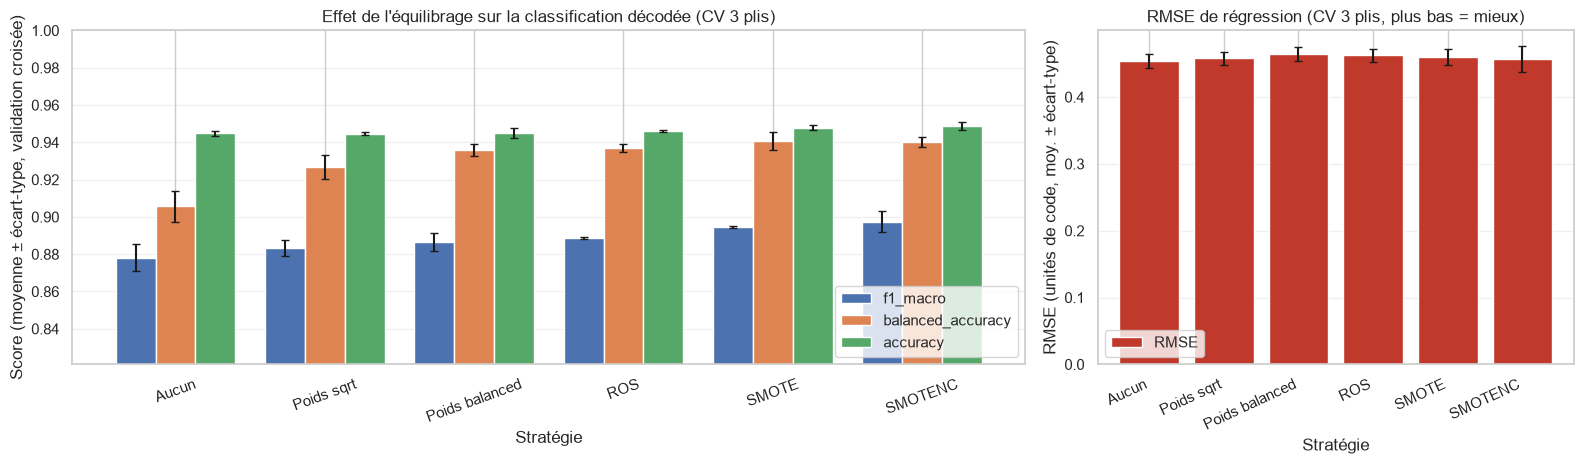

In [5]:
cv_rows = {}
for name in STRATS:
    t0 = time.time()
    folds = cv_folds(lambda: build(make_est(n_estimators=150), name), name)
    cv_rows[name] = mean_std(folds); print(f"  {name:<15} {time.time() - t0:6.1f}s")
cv_tab = pd.DataFrame(cv_rows).T
show = ["rmse", "rmse_std", "mae", "r2", "accuracy", "balanced_accuracy", "f1_macro", "f1_macro_std", "fit_s"]
display(cv_tab[show].round(4))
best_strat = U.select_by_parsimony(cv_tab, "f1_macro", "f1_macro_std", list(STRATS))
top = cv_tab["f1_macro"].idxmax()
print(f"Meilleure moyenne brute : {top} (F1 macro = {cv_tab.loc[top, 'f1_macro']:.4f} ± {cv_tab.loc[top, 'f1_macro_std']:.4f})")
print(f"=> Stratégie retenue (parcimonie) : {best_strat} (F1 macro = {cv_tab.loc[best_strat, 'f1_macro']:.4f} ± {cv_tab.loc[best_strat, 'f1_macro_std']:.4f})")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2, 1]})
U.plot_cv_comparison(cv_tab, ["f1_macro", "balanced_accuracy", "accuracy"], ["f1_macro_std", "balanced_accuracy_std", "accuracy_std"],
                     "Effet de l'équilibrage sur la classification décodée (CV 3 plis)", ax=axes[0])
axes[1].bar(range(len(cv_tab)), cv_tab["rmse"], yerr=cv_tab["rmse_std"], capsize=3, color="#c0392b", label="RMSE")
axes[1].set_xticks(range(len(cv_tab)), cv_tab.index, rotation=25, ha="right")
axes[1].set(title="RMSE de régression (CV 3 plis, plus bas = mieux)", xlabel="Stratégie", ylabel="RMSE (unités de code, moy. ± écart-type)")
axes[1].legend(); axes[1].grid(axis="y", alpha=.3)
plt.tight_layout(); U.savefig(fig, "05_balancing_cv"); plt.show()

Lecture : si plusieurs stratégies sont à moins d'un écart-type l'une de l'autre, la différence est du **bruit** de CV et la plus simple est conservée. Un gain de F1 macro obtenu au prix d'une
hausse du RMSE signale un compromis : le rééchantillonnage tire les prédictions des classes rares vers leur code, ce qui aide la classification mais peut dégrader l'erreur globale.

## 5. Réglage des hyper-paramètres
Recherche aléatoire (12 configurations × 3 plis) sur le sous-échantillon, avec la stratégie d'équilibrage retenue. Classement par **RMSE** (perte native) ; le F1 macro est affiché en parallèle.
Le nombre d'arbres est fixé à 150 pendant la recherche, puis déterminé par arrêt anticipé (§6).

In [6]:
space = {"max_depth": [4, 6, 8, 10], "learning_rate": [0.03, 0.06, 0.1, 0.2], "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.5, 0.7, 0.9, 1.0],
         "min_child_weight": [1, 3, 5, 10], "reg_lambda": [0.5, 1, 5, 10], "reg_alpha": [0, 0.1, 1], "gamma": [0, 0.1, 0.5]}
N_ITER = 12

In [7]:
fixed = {"n_estimators": 150}
configs, rows = [], []
for i, p in enumerate(ParameterSampler(space, n_iter=N_ITER, random_state=RS)):
    p = {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
    f = cv_folds(lambda: build(make_est(**{**fixed, **p}), best_strat), best_strat); r = f.mean(); configs.append(p)
    rows.append({**{k: str(v) for k, v in p.items()}, "rmse": r["rmse"], "f1_macro": r["f1_macro"], "accuracy": r["accuracy"], "fit_s": r["fit_s"]})
    print(f"  [{i+1}/{N_ITER}] rmse={r['rmse']:.4f} f1_macro={r['f1_macro']:.4f}  {p}")
tuning = pd.DataFrame(rows).sort_values("rmse"); display(tuning.head(8).round(4))
best_params = dict(configs[int(tuning.index[0])]); print("Meilleurs hyper-paramètres (RMSE CV) :", best_params)

  [1/12] rmse=0.5879 f1_macro=0.8184  {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.06, 'gamma': 0.1, 'colsample_bytree': 1.0}


  [2/12] rmse=0.4424 f1_macro=0.8971  {'subsample': 0.7, 'reg_lambda': 1, 'reg_alpha': 1, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.2, 'gamma': 0, 'colsample_bytree': 0.9}


  [3/12] rmse=0.4862 f1_macro=0.8643  {'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha': 1, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.06, 'gamma': 0, 'colsample_bytree': 0.5}


  [4/12] rmse=0.4777 f1_macro=0.8698  {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 1, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.06, 'gamma': 0.5, 'colsample_bytree': 0.5}


  [5/12] rmse=0.4957 f1_macro=0.8691  {'subsample': 1.0, 'reg_lambda': 10, 'reg_alpha': 0, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.06, 'gamma': 0, 'colsample_bytree': 1.0}


  [6/12] rmse=0.4375 f1_macro=0.9038  {'subsample': 0.7, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.03, 'gamma': 0.5, 'colsample_bytree': 0.7}


... (4 outputs left out)

  [11/12] rmse=0.4321 f1_macro=0.8992  {'subsample': 0.85, 'reg_lambda': 10, 'reg_alpha': 1, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.2, 'gamma': 0.1, 'colsample_bytree': 0.5}


  [12/12] rmse=0.5347 f1_macro=0.8487  {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}


,subsample,reg_lambda,reg_alpha,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,rmse,f1_macro,accuracy,fit_s
10,0.85,10,1,5,8,0.2,0.1,0.5,0.4321,0.8992,0.9544,2.2445
8,0.85,0.5,0,5,10,0.1,0.5,0.5,0.4326,0.9011,0.9544,2.3854
5,0.7,0.5,0.1,1,10,0.03,0.5,0.7,0.4375,0.9038,0.9547,19.7673
6,0.85,1,0.1,3,8,0.2,0.1,0.7,0.4377,0.9039,0.9563,12.5674
1,0.7,1,1,5,6,0.2,0,0.9,0.4424,0.8971,0.9517,4.0180
7,1.0,0.5,0.1,5,6,0.1,0,1.0,0.4593,0.8954,0.9488,11.2883
9,1.0,0.5,0,1,6,0.06,0.1,0.9,0.4742,0.8794,0.9376,2.5086
3,1.0,0.5,1,3,6,0.06,0.5,0.5,0.4777,0.8698,0.9319,4.7461


Meilleurs hyper-paramètres (RMSE CV) : {'subsample': 0.85, 'reg_lambda': 10, 'reg_alpha': 1, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.2, 'gamma': 0.1, 'colsample_bytree': 0.5}


## 6. Arrêt anticipé et modèle final
Un jeu de contrôle (10 % du train, stratifié sur `type`) sert à arrêter l'ajout d'arbres quand l'erreur ne baisse plus pendant 50 itérations — **pas** la validation, réservée au calibrage du décodage.
Le prétraitement (et le rééchantillonnage éventuel) est ajusté sur les 90 % restants uniquement ; le jeu de contrôle reste intact. Le modèle final est ensuite réentraîné sur **tout** le train avec ce nombre d'arbres.

Nombre d'arbres retenu (arrêt anticipé, jeu de contrôle du train) : 288


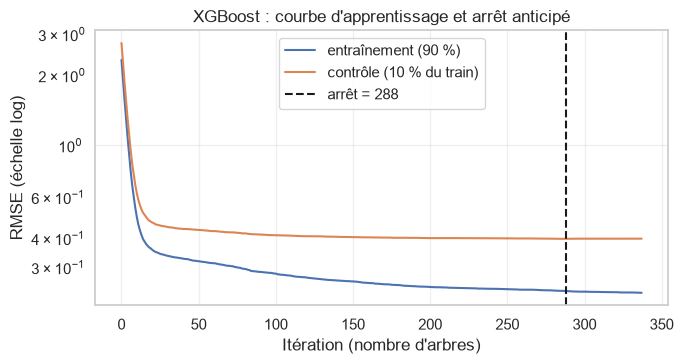

Réentraînement sur tout le train : 17.4s | stratégie : SMOTE | paramètres : {'subsample': 0.85, 'reg_lambda': 10, 'reg_alpha': 1, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.2, 'gamma': 0.1, 'colsample_bytree': 0.5, 'n_estimators': 288}


In [8]:
tr_i, ho_i = train_test_split(np.arange(len(X_train)), test_size=0.10, stratify=y_tr["type"], random_state=RS)
pipe_es = build(make_est(**{k: v for k, v in best_params.items() if k != "n_estimators"}), best_strat)
Xa, ya = prep_fit_resample(pipe_es.steps[:-1], X_train.iloc[tr_i], ytr[tr_i])
Xb = prep_transform(pipe_es.steps[:-1], X_train.iloc[ho_i])
w_a = class_weights(ya, STRATS[best_strat][1]); w_b = class_weights(ytr[ho_i], STRATS[best_strat][1])
kw = {} if w_a is None else {"sample_weight": w_a, "sample_weight_eval_set": [w_a, w_b]}
es = XGBRegressor(n_estimators=2000, early_stopping_rounds=50, eval_metric="rmse", objective="reg:squarederror", tree_method="hist", n_jobs=NJ, random_state=RS,
                  **{k: v for k, v in best_params.items() if k != "n_estimators"})
es.fit(Xa, ya, eval_set=[(Xa, ya), (Xb, ytr[ho_i])], verbose=False, **kw)
best_n = int(es.best_iteration) + 1; print(f"Nombre d'arbres retenu (arrêt anticipé, jeu de contrôle du train) : {best_n}")
hist = es.evals_result(); fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(hist["validation_0"]["rmse"], label="entraînement (90 %)"); ax.plot(hist["validation_1"]["rmse"], label="contrôle (10 % du train)"); ax.axvline(best_n, color="k", ls="--", label=f"arrêt = {best_n}")
ax.set(xlabel="Itération (nombre d'arbres)", ylabel="RMSE (échelle log)", title="XGBoost : courbe d'apprentissage et arrêt anticipé", yscale="log"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); U.savefig(fig, "05_learning_curve"); plt.show()
best_params["n_estimators"] = best_n
t0 = time.time(); final = fit_strat(build(make_est(**best_params), best_strat), X_train, ytr, best_strat); t_fit = time.time() - t0
print(f"Réentraînement sur tout le train : {t_fit:.1f}s | stratégie : {best_strat} | paramètres : {best_params}")

## 7. Évaluation en validation
Deux blocs **séparés** : régression (sortie continue) puis classification après décodage par arrondi. L'écart train / validation mesure le sur-apprentissage.

,mae,rmse,r2
Régression (sortie brute),,,
train,0.0660,0.2913,0.9925
validation,0.0854,0.3869,0.9867


,accuracy,balanced_accuracy,mcc,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
Classification (arrondi),,,,,,,,,
train,0.9726,0.9723,0.9678,0.9173,0.9723,0.9410,0.9753,0.9726,0.9732
validation,0.9650,0.9545,0.9589,0.8987,0.9545,0.9226,0.9684,0.9650,0.9660


,precision,recall,f1,support
normal,0.9998,0.9737,0.9866,4910
ransomware,0.7871,0.9919,0.8777,246
scanning,0.9540,0.9395,0.9467,1191
backdoor,0.8333,0.9897,0.9048,485
dos,0.9818,0.9722,0.9770,2878
mitm,0.5860,0.8227,0.6844,203
xss,0.9249,0.9593,0.9418,1745
ddos,0.9285,0.9687,0.9482,2655
injection,0.9920,0.9451,0.9680,3956
password,0.9997,0.9823,0.9909,3213


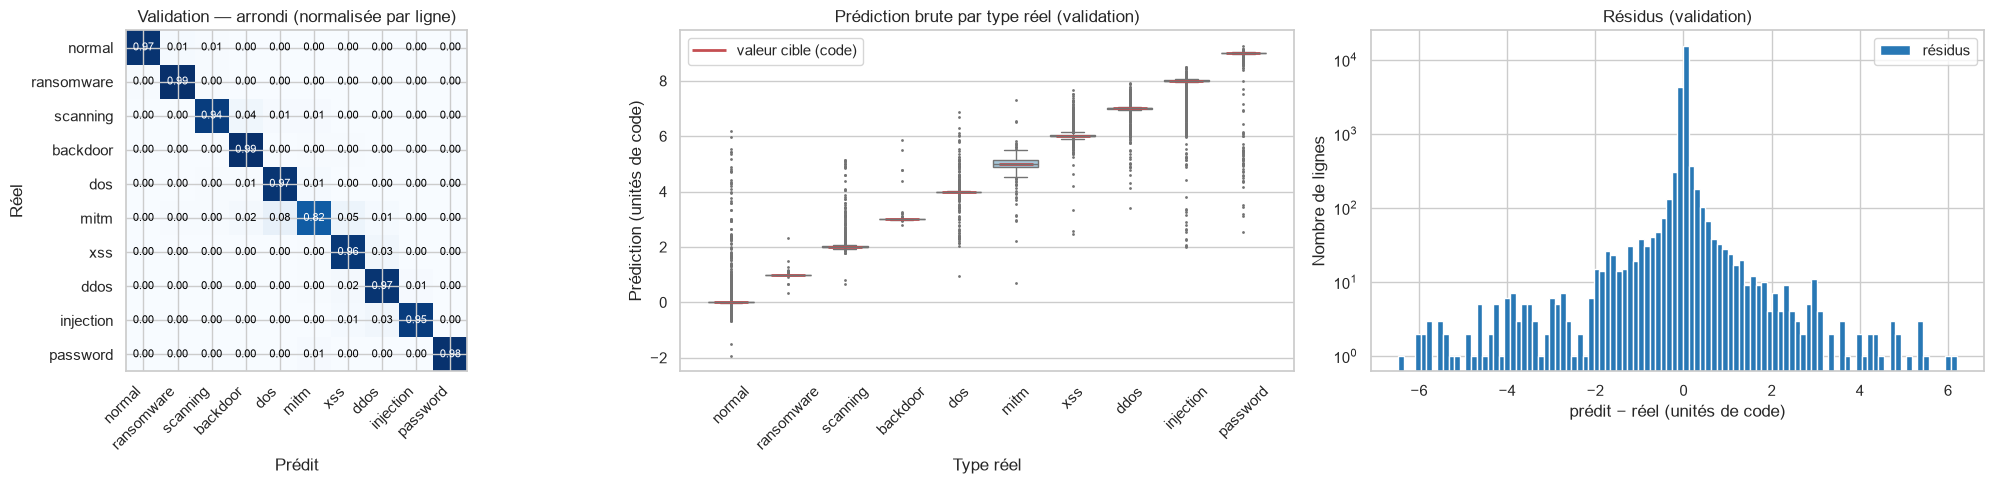

In [9]:
p_tr, p_va = final.predict(X_train), final.predict(X_valid)
display(pd.DataFrame({"train": U.regression_metrics(ytr, p_tr), "validation": U.regression_metrics(yva, p_va)}).T.round(4).rename_axis("Régression (sortie brute)"))
pred_va = U.decode_round(p_va, K)
display(pd.DataFrame({"train": eval_cls(ytr, p_tr), "validation": eval_cls(yva, p_va)}).T.round(4).rename_axis("Classification (arrondi)"))
display(U.per_class_report(yva, pred_va, LABELS, ORDER).round(4))
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
U.plot_confusion(confusion_matrix(yva, pred_va, labels=LABELS), ORDER, "Validation — arrondi (normalisée par ligne)", ax=axes[0], normalize=True)
sns.boxplot(x=pd.Categorical(y_va["type"], ORDER), y=p_va, ax=axes[1], fliersize=1, color="#9ecae1")
axes[1].plot(range(K), range(K), "r_", ms=25, mew=2, label="valeur cible (code)")
axes[1].set(title="Prédiction brute par type réel (validation)", xlabel="Type réel", ylabel="Prédiction (unités de code)"); axes[1].tick_params(axis="x", rotation=45); axes[1].legend()
axes[2].hist(p_va - yva, bins=100, color="#2878b5", label="résidus"); axes[2].set(title="Résidus (validation)", xlabel="prédit − réel (unités de code)", ylabel="Nombre de lignes", yscale="log"); axes[2].legend()
plt.tight_layout(); U.savefig(fig, "05_valid_eval"); plt.show()

## 8. Décodage : arrondi vs seuils optimisés
L'arrondi place les frontières à 0,5 ; 1,5 ; … Rien ne garantit qu'elles soient optimales (classes rares, erreurs asymétriques). On cherche les **9 seuils** qui maximisent le F1 macro
**sur la validation** (descente de coordonnées, `U.optimize_cutpoints`) puis on les applique tels quels au test. Les seuils sont ajustés sur la validation elle-même : le gain mesuré ici
est donc optimiste, d'où l'importance de la lecture sur le test.

In [10]:
cuts, f1_cut = U.optimize_cutpoints(p_va, yva, K)
default_cuts = np.arange(K - 1) + 0.5
print("Seuils optimisés :", cuts.round(3)); print("Seuils par défaut:", default_cuts)
pv_round, pv_cut = U.decode_with_cuts(p_va, default_cuts), U.decode_with_cuts(p_va, cuts)
def cls_block(y, pred):
    return {**U.multiclass_metrics(y, pred, LABELS), "within_1_class": U.within_k(y, pred, 1)}
cmp_ = pd.DataFrame({"arrondi": cls_block(yva, pv_round), "seuils optimisés": cls_block(yva, pv_cut)}).T
display(cmp_.round(4))
valid_gain = cmp_.loc["seuils optimisés", "f1_macro"] - cmp_.loc["arrondi", "f1_macro"]
print(f"Gain de F1 macro (validation, seuils appris sur cette même validation) : {valid_gain:+.4f}")

Seuils optimisés : [0.966 1.183 2.936 3.09  4.436 5.333 6.5   7.3   8.566]
Seuils par défaut: [0.5 1.5 2.5 3.5 4.5 5.5 6.5 7.5 8.5]


,accuracy,balanced_accuracy,mcc,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,within_1_class
arrondi,0.9650,0.9545,0.9589,0.8987,0.9545,0.9226,0.9684,0.9650,0.9660,0.9867
seuils optimisés,0.9687,0.9530,0.9632,0.9293,0.9530,0.9398,0.9703,0.9687,0.9692,0.9850


Gain de F1 macro (validation, seuils appris sur cette même validation) : +0.0172


## 9. Évaluation finale sur le test (lue une seule fois)
Aucune décision n'est prise ici : stratégie, hyper-paramètres, nombre d'arbres et seuils sont figés.

,mae,rmse,r2,accuracy,balanced_accuracy,mcc,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,within_1_class
arrondi,0.0822,0.3764,0.9874,0.9668,0.9554,0.9611,0.9044,0.9554,0.9263,0.9699,0.9668,0.9678,0.9876
seuils optimisés (valid),0.0822,0.3764,0.9874,0.9694,0.9497,0.9640,0.9283,0.9497,0.9377,0.9709,0.9694,0.9699,0.9864


,precision,recall,f1,support
normal,0.9985,0.9856,0.9920,4866
ransomware,0.9631,0.9514,0.9572,247
scanning,0.9305,0.9697,0.9497,1187
backdoor,0.9736,0.9876,0.9806,485
dos,0.9787,0.9715,0.9751,2882
mitm,0.5953,0.7727,0.6725,198
xss,0.9203,0.9593,0.9394,1745
ddos,0.9421,0.9616,0.9518,2657
injection,0.9806,0.9573,0.9688,3956
password,1.0000,0.9801,0.9899,3215


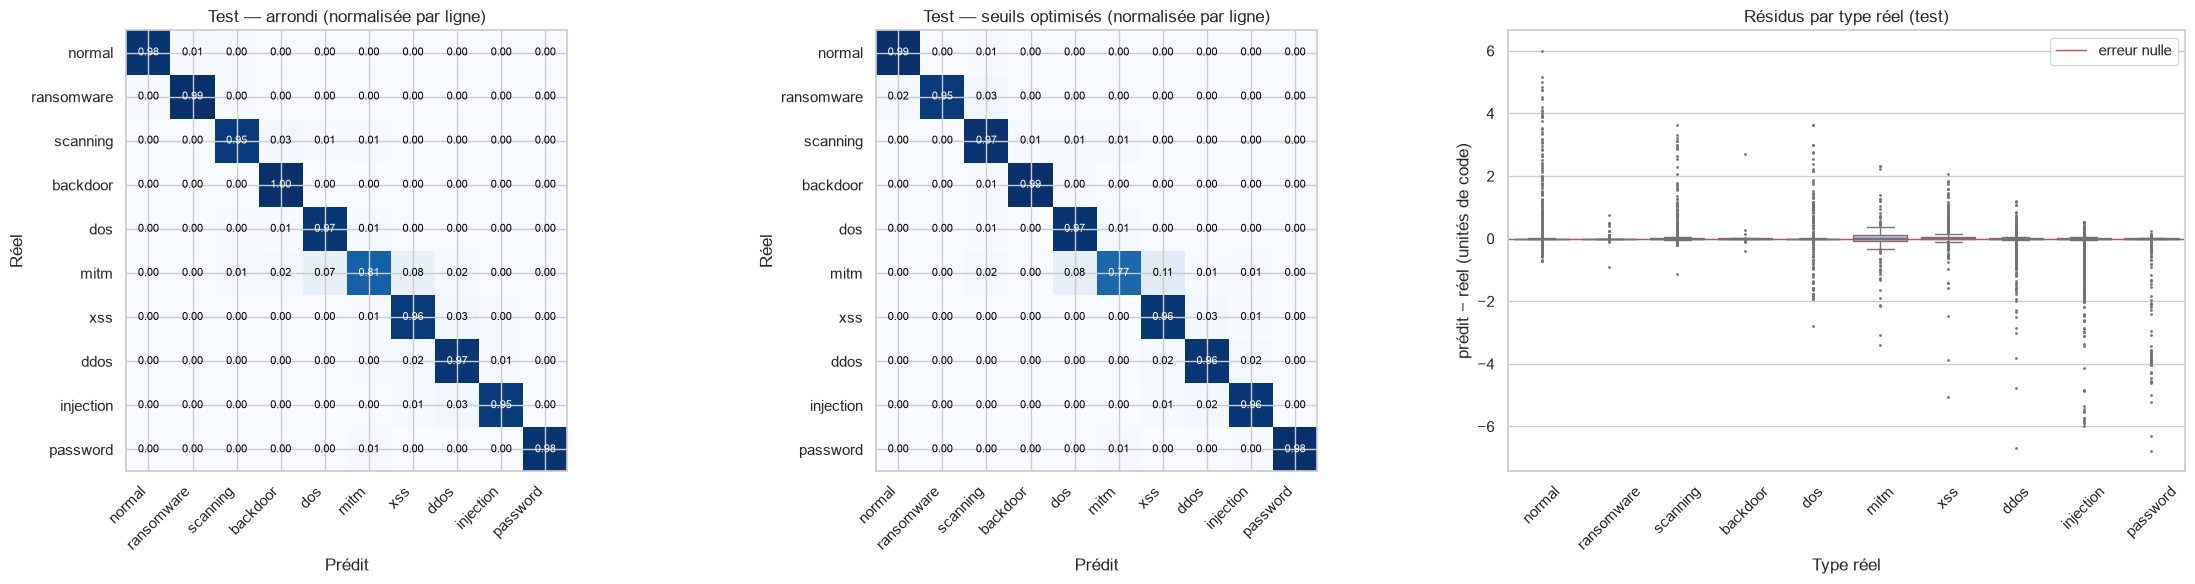

Temps de prédiction : 8.4 ms / 1000 lignes | entraînement final : 17.4 s sur 65007 lignes


In [11]:
p_te = final.predict(X_test)
pt_round, pt_cut = U.decode_with_cuts(p_te, default_cuts), U.decode_with_cuts(p_te, cuts)
reg_test = U.regression_metrics(yte, p_te)
test_round = {**reg_test, **cls_block(yte, pt_round)}
test_cut = {**reg_test, **cls_block(yte, pt_cut)}
display(pd.DataFrame({"arrondi": test_round, "seuils optimisés (valid)": test_cut}).T.round(4))
pc_test = U.per_class_report(yte, pt_cut, LABELS, ORDER); display(pc_test.round(4))
fig, axes = plt.subplots(1, 3, figsize=(23, 6))
U.plot_confusion(confusion_matrix(yte, pt_round, labels=LABELS), ORDER, "Test — arrondi (normalisée par ligne)", ax=axes[0], normalize=True)
U.plot_confusion(confusion_matrix(yte, pt_cut, labels=LABELS), ORDER, "Test — seuils optimisés (normalisée par ligne)", ax=axes[1], normalize=True)
sns.boxplot(x=pd.Categorical(y_te["type"], ORDER), y=p_te - yte, ax=axes[2], fliersize=1, color="#9ecae1"); axes[2].axhline(0, color="r", lw=1, label="erreur nulle")
axes[2].set(title="Résidus par type réel (test)", xlabel="Type réel", ylabel="prédit − réel (unités de code)"); axes[2].tick_params(axis="x", rotation=45); axes[2].legend()
plt.tight_layout(); U.savefig(fig, "05_test_confusions"); plt.show()
t_pred = U.measure_predict_time(final.predict, X_test)
print(f"Temps de prédiction : {t_pred:.1f} ms / 1000 lignes | entraînement final : {t_fit:.1f} s sur {len(X_train)} lignes")

## 10. Interprétation et rappel par type
Importances d'impureté (gain) du modèle final et importances par **permutation** (hausse du RMSE de validation sur 6 000 lignes, 3 répétitions).
Les importances d'impureté favorisent les variables à nombreuses modalités ; la permutation est plus fiable mais l'importance se répartit entre variables corrélées.

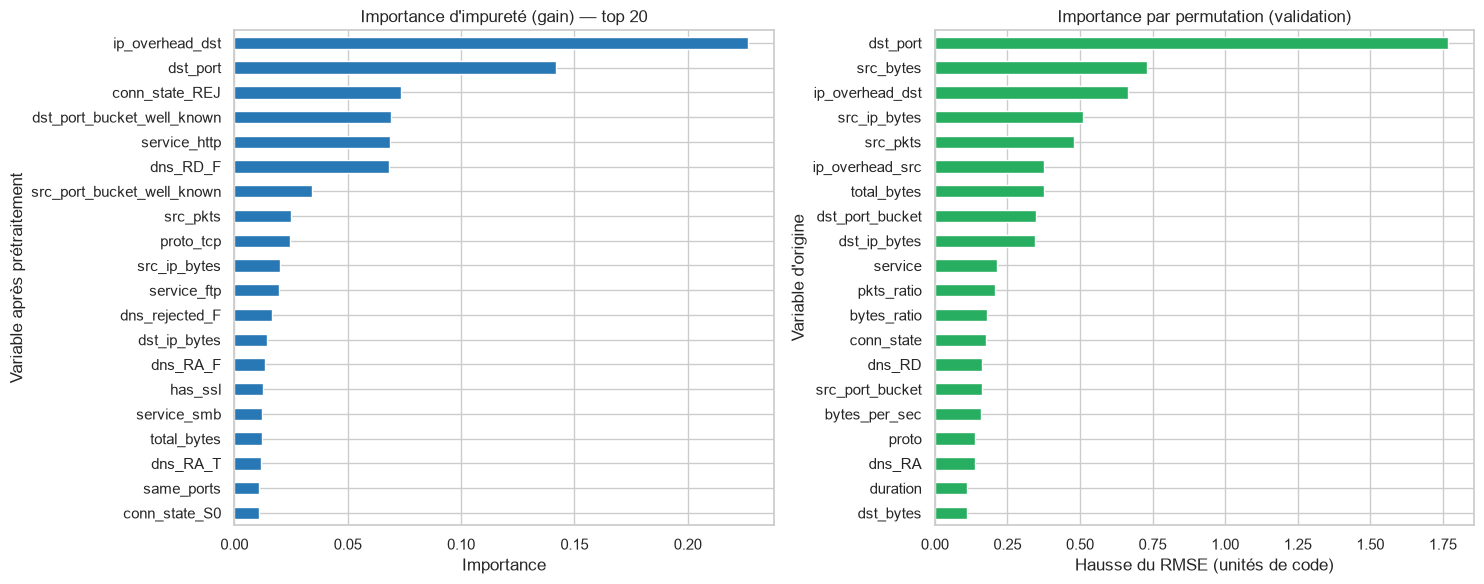

Top 5 permutation : dst_port (1.769), src_bytes (0.730), ip_overhead_dst (0.665), src_ip_bytes (0.511), src_pkts (0.479)
Top 5 impureté    : ip_overhead_dst (0.226), dst_port (0.142), conn_state_REJ (0.074), dst_port_bucket_well_known (0.069), service_http (0.069)


In [12]:
try:
    fn = list(final[:-1].get_feature_names_out())
    assert len(fn) == len(final.named_steps["model"].feature_importances_)
except Exception:
    fn = [f"x{i}" for i in range(len(final.named_steps["model"].feature_importances_))]
imp = pd.Series(final.named_steps["model"].feature_importances_, index=fn).sort_values(ascending=False)
sidx = X_valid.sample(6000, random_state=RS).index.to_numpy()
pi = permutation_importance(final, X_valid.loc[sidx], yva[sidx], scoring="neg_root_mean_squared_error", n_repeats=3, random_state=RS, n_jobs=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(20).iloc[::-1].plot(kind="barh", ax=axes[0], color="#2878b5")
axes[0].set(title="Importance d'impureté (gain) — top 20", xlabel="Importance", ylabel="Variable après prétraitement")
pd.Series(pi.importances_mean, index=X_valid.columns).sort_values().tail(20).plot(kind="barh", ax=axes[1], color="#27ae60")
axes[1].set(title="Importance par permutation (validation)", xlabel="Hausse du RMSE (unités de code)", ylabel="Variable d'origine")
plt.tight_layout(); U.savefig(fig, "05_importances"); plt.show()
perm_top = pd.Series(pi.importances_mean, index=X_valid.columns).sort_values(ascending=False).head(5)
print("Top 5 permutation :", ", ".join(f"{k} ({v:.3f})" for k, v in perm_top.items()))
print("Top 5 impureté    :", ", ".join(f"{k} ({v:.3f})" for k, v in imp.head(5).items()))

In [13]:
d = pd.DataFrame({"type": y_te["type"].to_numpy(), "code": yte, "pred": p_te, "cls": pt_cut})
by_type = d.groupby("type").apply(lambda g: pd.Series({"n": len(g), "MAE": np.abs(g.pred - g.code).mean(),
        "rappel": (g.cls == g.code).mean(), "erreur_>1_code": (np.abs(g.cls - g.code) > 1).mean()})).loc[ORDER]
display(by_type.round(4))

,n,MAE,rappel,erreur_>1_code
type,,,,
normal,4866.0000,0.0687,0.9856,0.0125
ransomware,247.0000,0.0243,0.9514,0.0000
scanning,1187.0000,0.1052,0.9697,0.0244
backdoor,485.0000,0.0154,0.9876,0.0021
dos,2882.0000,0.0541,0.9715,0.0135
mitm,198.0000,0.3340,0.7727,0.0354
xss,1745.0000,0.1084,0.9593,0.0092
ddos,2657.0000,0.0677,0.9616,0.0045
injection,3956.0000,0.1132,0.9573,0.0195


## 11. Classifieur de référence — *non demandé* (XGBClassifier (multi:softprob))
**Section de référence, hors périmètre du sujet** (qui impose un régresseur). Elle répond à une question précise : que perd-on à prédire un type nominal par une régression ?
Mêmes variables, même stratégie d'équilibrage (celle retenue en §4), mêmes hyper-paramètres que le régresseur, réentraîné sur tout le train ; aucun réglage propre. Le classifieur prédit
directement la classe : il n'a besoin ni d'ordre des codes, ni de décodage. Il n'est **pas** le modèle livré pour la tâche de régression.

Référence (XGBClassifier (multi:softprob)) : entraînement 43.0s | prédiction 17.4 ms / 1000 lignes


,accuracy,balanced_accuracy,mcc,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,within_1_class
"Test, classification",,,,,,,,,,
régresseur — arrondi,0.9668,0.9554,0.9611,0.9044,0.9554,0.9263,0.9699,0.9668,0.9678,0.9876
régresseur — seuils,0.9694,0.9497,0.9640,0.9283,0.9497,0.9377,0.9709,0.9694,0.9699,0.9864
classifieur de référence,0.9826,0.9771,0.9796,0.9489,0.9771,0.9605,0.9842,0.9826,0.9832,0.9871


,régresseur (seuils),classifieur de référence
normal,0.9920,0.9962
ransomware,0.9572,0.9919
scanning,0.9497,0.9728
backdoor,0.9806,0.9969
dos,0.9751,0.9844
mitm,0.6725,0.7427
xss,0.9394,0.9637
ddos,0.9518,0.9860
injection,0.9688,0.9790
password,0.9899,0.9916


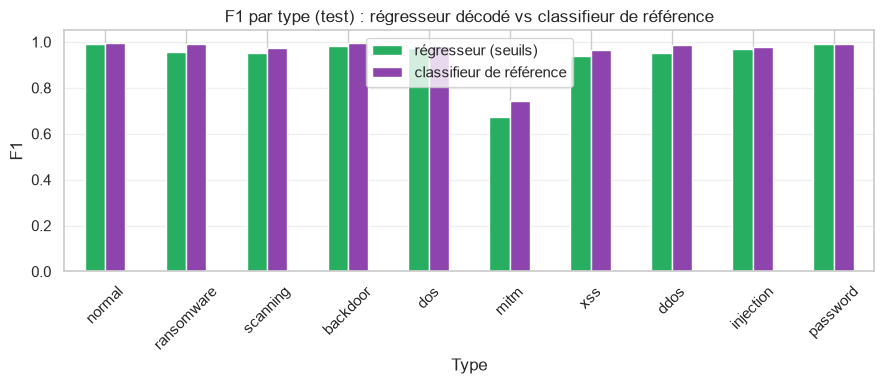

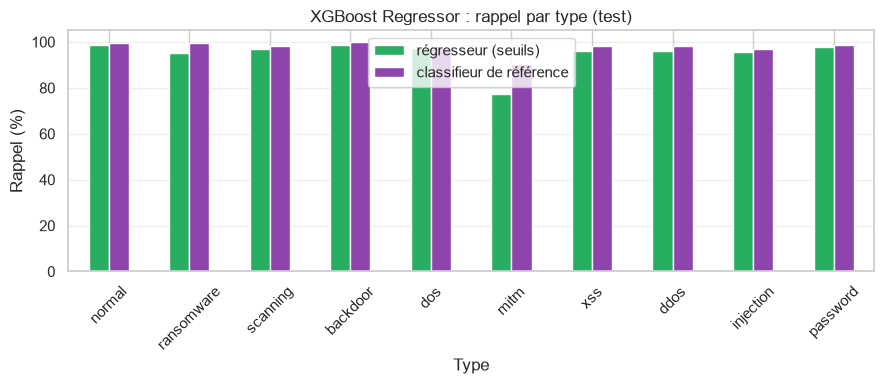

In [14]:
t0 = time.time(); ref = fit_strat(build(XGBClassifier(objective="multi:softprob", num_class=K, tree_method="hist", n_jobs=NJ, random_state=RS, **best_params), best_strat), X_train, ytr, best_strat); t_fit_ref = time.time() - t0
pr_va, pr_te = ref.predict(X_valid), ref.predict(X_test)
t_pred_ref = U.measure_predict_time(ref.predict, X_test)
ref_valid = U.multiclass_metrics(yva, pr_va, LABELS)
ref_test = {**U.multiclass_metrics(yte, pr_te, LABELS), "within_1_class": U.within_k(yte, pr_te, 1)}
pc_ref = U.per_class_report(yte, pr_te, LABELS, ORDER)
print(f"Référence (XGBClassifier (multi:softprob)) : entraînement {t_fit_ref:.1f}s | prédiction {t_pred_ref:.1f} ms / 1000 lignes")
display(pd.DataFrame({"régresseur — arrondi": {k: v for k, v in test_round.items() if k not in ("mae", "rmse", "r2")},
                      "régresseur — seuils": {k: v for k, v in test_cut.items() if k not in ("mae", "rmse", "r2")},
                      "classifieur de référence": ref_test}).T.round(4).rename_axis("Test, classification"))
f1c = pd.DataFrame({"régresseur (seuils)": pc_test["f1"], "classifieur de référence": pc_ref["f1"]})
display(f1c.round(4))
fig, ax = plt.subplots(figsize=(9, 4)); f1c.plot(kind="bar", ax=ax, color=["#27ae60", "#8e44ad"])
ax.set(title="F1 par type (test) : régresseur décodé vs classifieur de référence", xlabel="Type", ylabel="F1", ylim=(0, 1.05)); ax.tick_params(axis="x", rotation=45); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); U.savefig(fig, "05_f1_by_type"); plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
rec = pd.DataFrame({"régresseur (seuils)": by_type["rappel"] * 100, "classifieur de référence": pc_ref["recall"] * 100}); rec.plot(kind="bar", ax=ax, color=["#27ae60", "#8e44ad"])
ax.set(ylabel="Rappel (%)", xlabel="Type", title="XGBoost Regressor : rappel par type (test)", ylim=(0, 105)); ax.tick_params(axis="x", rotation=45); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); U.savefig(fig, "05_recall_by_type"); plt.show()

## 12. Sauvegarde

In [15]:
joblib.dump(final, U.MODEL_DIR / "xgb_type_regressor.joblib", compress=3)
joblib.dump(ref, U.MODEL_DIR / "xgb_type_classifier_ref.joblib", compress=3)
limitations = [
    "Cible nominale traitée comme un code entier : l'ordre des codes est un artefact (étudié en 01), l'indicateur ±1 code est faiblement interprétable.",
    "Les seuils de décodage sont appris sur la validation (une seule dimension, intervalles contigus) : ils corrigent partiellement l'artefact d'ordre.",
    f"Classe la plus rare (mitm) : {int(np.bincount(ytr, minlength=K)[T2C['mitm']])} lignes d'entraînement ; le F1 de cette classe est très incertain.",
    "Réglage et comparaison d'équilibrage sur un sous-échantillon de 40 000 lignes (CV 3 plis) : les différences inférieures à un écart-type sont du bruit.",
    "Le classifieur de référence réutilise les hyper-paramètres du régresseur sans réglage propre : il sous-estime peut-être ce qu'un classifieur réglé atteindrait.",
    "Données de banc d'essai TON_IoT dédupliquées en 01 ; la généralisation à un autre réseau n'est pas mesurée.",
]
U.save_result("05_xgb_regressor", {
    "task": "Prédiction du type d'attaque (régression sur code entier, décodée en classe)", "model": "XGBoost Regressor", "strategy": best_strat,
    "params": best_params, "type_order": ORDER, "n_train_rows": int(len(X_train)), "fit_time_s": float(t_fit), "predict_time_ms_per_1k": float(t_pred),
    "cutpoints": cuts, "cv": cv_tab, "tuning_top": tuning.head(8), "baseline_valid": base_valid,
    "valid": {**U.regression_metrics(yva, p_va), **cls_block(yva, pv_cut)},
    "valid_rounded": {**U.regression_metrics(yva, p_va), **cls_block(yva, pv_round)},
    "test": test_cut, "test_rounded": test_round, "per_class": pc_test, "recall_by_type": by_type["rappel"],
    "reference_classifier": {"label": "référence — non demandé", "model": "XGBClassifier (multi:softprob)", "strategy": best_strat, "params": best_params,
        "fit_time_s": float(t_fit_ref), "predict_time_ms_per_1k": float(t_pred_ref), "valid": ref_valid, "test": ref_test,
        "per_class_f1": pc_ref["f1"], "per_class": pc_ref},
    "limitations": limitations})
print("Modèles et résultats sauvegardés.")

Modèles et résultats sauvegardés.


## Conclusion (générée à partir des résultats ci-dessus)

In [16]:
g = test_cut["f1_macro"] - test_round["f1_macro"]
gap_ref = ref_test["f1_macro"] - test_cut["f1_macro"]
worst, best = pc_test["f1"].idxmin(), pc_test["f1"].idxmax()
lines = [
 f"- **Encodage** : ordre `{', '.join(ORDER)}` ({cfg['type_order_source']}). Cible nominale : l'ordre reste un artefact (voir §1).",
 f"- **Équilibrage (CV)** : stratégie retenue par parcimonie = **{best_strat}** (F1 macro CV {cv_tab.loc[best_strat, 'f1_macro']:.3f} ± {cv_tab.loc[best_strat, 'f1_macro_std']:.3f} ; meilleure moyenne brute : {top}, {cv_tab.loc[top, 'f1_macro']:.3f}).",
 f"- **Hyper-paramètres** : {best_params}.",
 f"- **Régression (test)** : MAE {reg_test['mae']:.3f}, RMSE {reg_test['rmse']:.3f}, R² {reg_test['r2']:.3f}.",
 f"- **Classification (test)** : F1 macro {test_round['f1_macro']:.3f} après arrondi, {test_cut['f1_macro']:.3f} avec seuils optimisés ({g:+.3f} ; accuracy {test_cut['accuracy']:.3f}, MCC {test_cut['mcc']:.3f}).",
 f"- **Par type** : meilleur F1 = {best} ({pc_test.loc[best, 'f1']:.3f}), plus faible = {worst} ({pc_test.loc[worst, 'f1']:.3f}, {int(pc_test.loc[worst, 'support'])} lignes de test).",
 f"- **Classifieur de référence (non demandé)** : F1 macro test {ref_test['f1_macro']:.3f} ({gap_ref:+.3f} vs régresseur à seuils) : écart mesuré entre classification directe et régression décodée.",
 f"- **Coût** : entraînement {t_fit:.1f} s sur {len(X_train)} lignes ; prédiction {t_pred:.1f} ms / 1000 lignes.",
 "- **Limites** : voir la liste `limitations` du JSON (artefact d'ordre, classe mitm rare, sous-échantillon pour le réglage, référence non réglée).",
]
display(Markdown("\n".join(lines)))

- **Encodage** : ordre `normal, ransomware, scanning, backdoor, dos, mitm, xss, ddos, injection, password` (piloté par les données (LDA, train)). Cible nominale : l'ordre reste un artefact (voir §1).
- **Équilibrage (CV)** : stratégie retenue par parcimonie = **SMOTE** (F1 macro CV 0.895 ± 0.000 ; meilleure moyenne brute : SMOTENC, 0.897).
- **Hyper-paramètres** : {'subsample': 0.85, 'reg_lambda': 10, 'reg_alpha': 1, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.2, 'gamma': 0.1, 'colsample_bytree': 0.5, 'n_estimators': 288}.
- **Régression (test)** : MAE 0.082, RMSE 0.376, R² 0.987.
- **Classification (test)** : F1 macro 0.926 après arrondi, 0.938 avec seuils optimisés (+0.011 ; accuracy 0.969, MCC 0.964).
- **Par type** : meilleur F1 = normal (0.992), plus faible = mitm (0.673, 198 lignes de test).
- **Classifieur de référence (non demandé)** : F1 macro test 0.961 (+0.023 vs régresseur à seuils) : écart mesuré entre classification directe et régression décodée.
- **Coût** : entraînement 17.4 s sur 65007 lignes ; prédiction 8.4 ms / 1000 lignes.
- **Limites** : voir la liste `limitations` du JSON (artefact d'ordre, classe mitm rare, sous-échantillon pour le réglage, référence non réglée).